# Semana 2 · Laboratorio 2: estimación de pose humana con YOLO
**Maestría en Inteligencia Artificial · Visión Artificial · Google Colab**

**Objetivo:** identificar los 17 puntos corporales (formato COCO), visualizar el esqueleto y calcular ángulos de articulaciones. Conectar los resultados con el caso de bienestar postural de **Nodo**.

**Referencia:** repositorio `eugeniomorocho/ComputerVision`, unidad `UC.05 Image Segmentation & Pose Estimation`, notebook `1. Pose estimation with YOLO.ipynb`.

**Adaptación docente:** se agregan descarga automática de recursos, medición de tiempos, ángulos y análisis de limitaciones. No es una copia literal del notebook original.

**Tiempo sugerido en clase:** 30–40 minutos. Funciona con CPU; GPU opcional.


## 1. Preparar el entorno
Funciona en **Google Colab**, **Windows** y **macOS**. En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución**. GPU opcional. Si al instalar OpenCV el kernel ya lo tenía cargado, reinicia el entorno y vuelve a ejecutar desde esta sección.

**Concepto:** *pose estimation* estima coordenadas de articulaciones en la imagen; no mide por sí sola la postura tridimensional ni diagnostica problemas médicos.


In [1]:
# OpenCV 4.11 coincide con el otro laboratorio. imageio-ffmpeg aporta FFmpeg en Windows y macOS.
%pip -q install -U ultralytics "opencv-python-headless==4.11.0.86" "imageio-ffmpeg>=0.5.1"
# OpenCV procesa imágenes y videos; PyTorch gestiona el cómputo; NumPy opera con vectores.
import cv2, torch, numpy as np, matplotlib.pyplot as plt, time, platform, shutil
# Path facilita el manejo de rutas y YOLO permite cargar modelos preentrenados.
from pathlib import Path
from ultralytics import YOLO

def en_colab():
    # google.colab solo existe dentro de Google Colab.
    try:
        import google.colab
        return True
    except ImportError:
        return False

def ruta_ffmpeg():
    # Si el sistema ya tiene FFmpeg (Colab, o una instalación local), lo usamos.
    encontrado = shutil.which("ffmpeg")
    if encontrado:
        return encontrado
    # En Windows y macOS sin FFmpeg, imageio-ffmpeg trae un binario con libx264.
    try:
        import imageio_ffmpeg
    except ImportError as e:
        raise RuntimeError(
            "No hay FFmpeg. Ejecuta de nuevo la celda de instalación y, si el kernel ya estaba abierto, reinícialo."
        ) from e
    return imageio_ffmpeg.get_ffmpeg_exe()

def solicitar_archivo(descripcion):
    # Colab muestra el selector. En local se pega la ruta, válida en Windows y macOS.
    if en_colab():
        from google.colab import files
        print(descripcion)
        subidos = files.upload()
        if not subidos:
            raise RuntimeError("No se proporcionó archivo")
        return str(Path(next(iter(subidos))).resolve())
    print(descripcion)
    print("Pega la ruta completa y presiona Enter.")
    print(r"Windows: C:\Users\tu_usuario\archivo.mp4")
    print("macOS: /Users/tu_usuario/archivo.mp4")
    ruta = input("Ruta: ").strip().strip('"').strip("'")
    if not ruta:
        raise RuntimeError("No se proporcionó archivo")
    origen = Path(ruta).expanduser()
    if not origen.is_file():
        raise FileNotFoundError(f"No existe el archivo: {origen}")
    return str(origen.resolve())

# Comprobamos GPU, sistema operativo y qué FFmpeg quedó disponible.
print("OpenCV:", cv2.__version__, "| GPU:", torch.cuda.is_available())
print("Entorno:", "Google Colab" if en_colab() else f"Local ({platform.system()})")
print("FFmpeg:", ruta_ffmpeg())
# Si hay GPU, usamos el dispositivo 0; en caso contrario, ejecutamos sobre CPU.
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
OpenCV: 4.11.0 | GPU: False
Entorno: Local (Darwin)
FFmpeg: /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/imageio_ffmpeg/binaries/ffmpeg-macos-aarch64-v7.1


## 2. Descargar imágenes y video de referencia
Usaremos `zuck_running.jpg` y `jesper.mp4`, presentes en la carpeta UC.05 del repositorio. **Si GitHub no permite descargar alguno, en Colab puedes subir un archivo y en Windows o macOS indicar su ruta**.

Para la actividad con personas, usar únicamente material con autorización.


In [2]:
# Requests descarga archivos. Si falla, Colab pide subirlos y en local se indica la ruta.
import requests
# quote convierte espacios y caracteres especiales en una ruta URL válida.
from urllib.parse import quote

# Dirección del repositorio y carpeta que contienen los recursos del laboratorio.
BASE = "https://raw.githubusercontent.com/eugeniomorocho/ComputerVision/main/"
CARPETA = "UC.05 Image Segmentation & Pose Estimation/"

# Descargamos el recurso solo si no existe ya una copia local válida.
def obtener_recurso(nombre):
    destino = Path(nombre)
    if destino.exists() and destino.stat().st_size > 1000:
        return str(destino)
    # Construimos la URL del archivo dentro del repositorio.
    url = BASE + quote(CARPETA + nombre, safe="/")
    try:
        r = requests.get(url, timeout=90)
        r.raise_for_status()
        destino.write_bytes(r.content)
        # Rechazamos archivos demasiado pequeños o referencias Git LFS en lugar del contenido real.
        if destino.stat().st_size < 1000 or r.content.startswith(b"version https://git-lfs"):
            destino.unlink(missing_ok=True)
            raise ValueError("Archivo pequeño o puntero Git LFS")
        print(f"Descargado: {nombre} ({destino.stat().st_size/1024**2:.1f} MB)")
        return str(destino)
    except Exception as e:
        # Colab abre el selector; Windows y macOS piden la ruta del archivo equivalente.
        print(f"No se pudo descargar {nombre}: {e}")
        return solicitar_archivo(f"Indica un archivo equivalente a {nombre}.")

# Obtenemos las rutas locales de la fotografía y del video.
IMAGEN = obtener_recurso("zuck_running.jpg")
VIDEO = obtener_recurso("jesper.mp4")
# Validamos que OpenCV pueda abrir ambos archivos antes de iniciar la inferencia.
assert cv2.imread(IMAGEN) is not None, "Imagen inválida"
cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), "Video inválido"
# Consultamos FPS y cantidad de cuadros para estimar la duración del video.
fps = cap.get(cv2.CAP_PROP_FPS)
frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
print(f"Video: {frames:.0f} frames, {fps:.1f} FPS, duración {frames/fps:.1f} s" if fps else "FPS no disponible")
# Cerramos el archivo para liberar recursos.
cap.release()


Descargado: zuck_running.jpg (0.1 MB)
Descargado: jesper.mp4 (21.3 MB)
Video: 4166 frames, 24.0 FPS, duración 173.6 s


## 3. Modelo de pose preentrenado
Usamos `yolo11n-pose.pt`, un modelo ligero compatible con Ultralytics. No requiere entrenamiento adicional.

Los puntos corporales COCO están indexados del 0 al 16. Por ejemplo: hombro izquierdo 5, codo izquierdo 7, muñeca izquierda 9; cadera izquierda 11, rodilla izquierda 13, tobillo izquierdo 15.


In [3]:
# Medimos cuánto tarda la carga del modelo.
inicio = time.perf_counter()
# YOLO11n-pose es una variante ligera, preentrenada para localizar articulaciones humanas.
modelo = YOLO("yolo11n-pose.pt")
# Informamos el tiempo de carga y el dispositivo seleccionado.
print("Modelo cargado en", round(time.perf_counter()-inicio, 2), "segundos")
print("Dispositivo:", DISPOSITIVO)


Modelo cargado en 4.35 segundos
Dispositivo: cpu


## 4. Inferencia sobre una fotografía
El modelo devuelve **cajas de personas** y **keypoints** con coordenadas y confianza.


Inferencia: 4.58 s
Personas detectadas: 4
Forma de keypoints: (4, 17, 3)


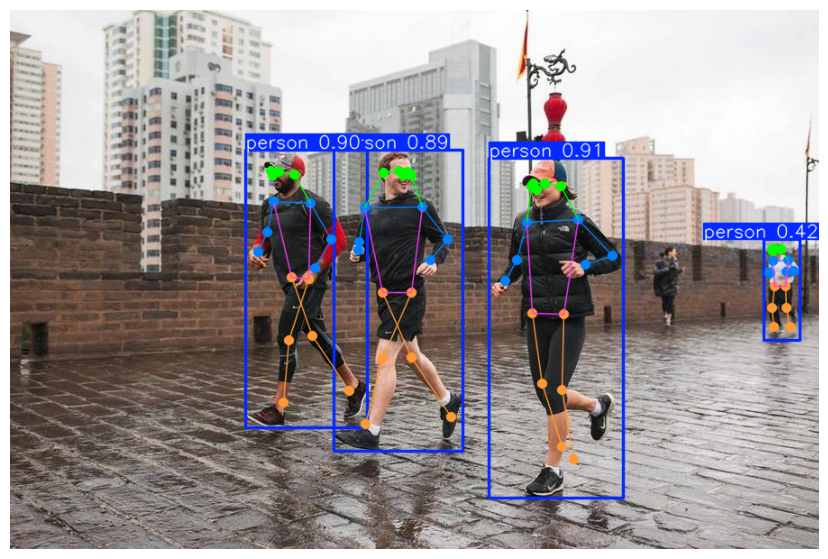

In [4]:
# Iniciamos el cronómetro de inferencia.
inicio = time.perf_counter()
# Ejecutamos el modelo sobre la fotografía a resolución de entrada 640; [0] extrae el primer resultado.
pred = modelo.predict(IMAGEN, device=DISPOSITIVO, imgsz=640, verbose=False)[0]
print("Inferencia:", round(time.perf_counter()-inicio, 2), "s")
# Mostramos duración, cantidad de personas y dimensiones de los puntos clave detectados.
print("Personas detectadas:", len(pred.boxes))
print("Forma de keypoints:", None if pred.keypoints is None else tuple(pred.keypoints.data.shape))
imagen_anotada = cv2.cvtColor(pred.plot(), cv2.COLOR_BGR2RGB)
# pred.plot() dibuja cajas y esqueleto; convertimos BGR a RGB para Matplotlib.
plt.figure(figsize=(11,7)); plt.imshow(imagen_anotada); plt.axis("off"); plt.show()


## 5. Calcular ángulos corporales
Ángulo de **codo izquierdo**: hombro (5) → codo (7) → muñeca (9). Ángulo de **rodilla izquierda**: cadera (11) → rodilla (13) → tobillo (15).

Son **ángulos proyectados en 2D**: cambian según la perspectiva de cámara y no equivalen a medidas biomecánicas 3D.


In [5]:
# Calcula el ángulo en grados formado por tres puntos 2D, con vértice en b.
def angulo_2d(a, b, c):
    # Convertimos los tres puntos en arreglos numéricos.
    a, b, c = map(lambda p: np.asarray(p, dtype=float), (a,b,c))
    # Construimos dos vectores desde la articulación central hacia sus extremos.
    v1, v2 = a-b, c-b
    # Evitamos divisiones por cero si alguno de los vectores tiene longitud casi nula.
    if np.linalg.norm(v1)<1e-8 or np.linalg.norm(v2)<1e-8:
        return np.nan
    # Producto punto normalizado: coseno del ángulo; clip evita errores numéricos fuera de [-1, 1].
    coseno = np.clip(np.dot(v1,v2)/(np.linalg.norm(v1)*np.linalg.norm(v2)), -1, 1)
    # arccos recupera el ángulo y degrees lo convierte de radianes a grados.
    return float(np.degrees(np.arccos(coseno)))

# Obtiene el ángulo de una articulación para una persona detectada, validando sus keypoints.
def angulo_persona(resultado, persona, indices, conf_min=0.35):
    # Si el modelo no produjo puntos clave, no podemos calcular el ángulo.
    if resultado.keypoints is None or resultado.keypoints.xy is None:
        return None
    # Extraemos las coordenadas (x, y) de los keypoints de la persona.
    xy = resultado.keypoints.xy[persona].cpu().numpy()
    conf = resultado.keypoints.conf
    # Descartamos mediciones cuando algún punto tiene confianza inferior al mínimo.
    if conf is not None:
        valores = conf[persona].cpu().numpy()
        if any(valores[k] < conf_min for k in indices):
            return None
    # Seleccionamos los tres puntos y descartamos coordenadas faltantes representadas como (0, 0).
    puntos = xy[list(indices)]
    if np.any(np.all(np.isclose(puntos, 0), axis=1)):
        return None
    return angulo_2d(*puntos)
    # Calculamos el ángulo únicamente cuando las coordenadas son utilizables.

for persona in range(len(pred.boxes)):
# Recorremos cada persona y medimos codo izquierdo (5,7,9) y rodilla izquierda (11,13,15).
    codo = angulo_persona(pred, persona, (5,7,9))
    rodilla = angulo_persona(pred, persona, (11,13,15))
    print(f"Persona {persona+1}: codo izq. = {codo if codo is not None else 'no confiable'}; "
    # Mostramos los ángulos o indicamos que la medición no es confiable.
          f"rodilla izq. = {rodilla if rodilla is not None else 'no confiable'}")


Persona 1: codo izq. = 63.913310639985234; rodilla izq. = 169.52793689424496
Persona 2: codo izq. = 121.34209109972477; rodilla izq. = 166.62650926206808
Persona 3: codo izq. = 102.85938548819993; rodilla izq. = 170.87841721787086
Persona 4: codo izq. = 71.56990713749144; rodilla izq. = 172.15394045669424


## 6. Aplicar el modelo a un video
Para limitar tiempos de CPU, por defecto procesaremos **hasta 300 frames**. El video generado incluye esqueletos y, cuando haya confianza suficiente, ángulo de codo izquierdo.

**Nota:** esta demostración no mantiene IDs entre personas; eso corresponde al laboratorio de ByteTrack.


In [6]:
# Importamos herramientas para reproducir el video en Colab, Windows o macOS.
from IPython.display import Video, display

# Limitamos el procesamiento a 300 cuadros para reducir tiempo y consumo de recursos.
MAX_FRAMES = 300  # Cambiar a None para procesar el video completo
# Abrimos el video y consultamos sus propiedades para conservar tamaño y velocidad.
entrada = cv2.VideoCapture(VIDEO)
fps = entrada.get(cv2.CAP_PROP_FPS) or 25
w = int(entrada.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(entrada.get(cv2.CAP_PROP_FRAME_HEIGHT))
salida = "pose_anotado.mp4"
# Preparamos un archivo MP4 de salida con la misma resolución y FPS del original.
writer = cv2.VideoWriter(salida, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w,h))
assert writer.isOpened(), "No se pudo crear el video de salida"
conteo, con_personas = 0, 0
# Inicializamos contadores y cronómetro de rendimiento.
inicio = time.perf_counter()
try:
    while MAX_FRAMES is None or conteo < MAX_FRAMES:
    # Leemos cuadros hasta alcanzar el límite o el final del video.
        ok, frame = entrada.read()
        # Si el video terminó, salimos del ciclo.
        if not ok:
            break
        res = modelo.predict(frame, device=DISPOSITIVO, imgsz=640, verbose=False)[0]
        dibujado = res.plot()
        # Estimamos la pose de las personas presentes en el cuadro actual.
        if len(res.boxes):
        # Dibujamos las cajas y los esqueletos detectados.
            con_personas += 1
        for p in range(len(res.boxes)):
        # Contamos los cuadros donde se detectó al menos una persona.
            ang = angulo_persona(res, p, (5,7,9))
            if ang is not None:
        # Calculamos el ángulo del codo izquierdo para cada persona.
                x1, y1, _, _ = res.boxes.xyxy[p].cpu().numpy().astype(int)
                cv2.putText(dibujado, f"Codo izq: {ang:.0f} deg",
                            (max(0,x1), max(25,y1-10)),
                # Ubicamos el texto cerca de la caja de la persona.
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255,255,255), 2)
                # Escribimos el ángulo sobre el cuadro anotado.
        writer.write(dibujado)
        conteo += 1
finally:
        # Guardamos el cuadro procesado en el video de salida.
    entrada.release()
    writer.release()
segundos = time.perf_counter()-inicio
    # Liberamos ambos archivos incluso si ocurre una excepción.
print(f"Frames: {conteo} | tiempo: {segundos:.1f}s | rendimiento: {conteo/segundos:.1f} FPS")
print(f"Frames con personas: {con_personas}")


Frames: 300 | tiempo: 12.3s | rendimiento: 24.5 FPS
Frames con personas: 185


## 7. Reproducir el resultado
Convertimos el archivo a H.264 para visualizarlo en el navegador. En Colab se usa el FFmpeg del sistema; en Windows y macOS, el de `imageio-ffmpeg` si no hay uno instalado.


In [7]:
# Convertimos a H.264 para que el video se vea en Colab y en Jupyter de Windows o macOS.
import subprocess
# Nombre del archivo convertido a H.264.
convertido = "pose_anotado_h264.mp4"
# libx264 codifica el video, yuv420p mejora compatibilidad y -an elimina audio.
subprocess.run([ruta_ffmpeg(),"-y","-loglevel","error","-i",salida,
                "-c:v","libx264","-preset","fast","-pix_fmt","yuv420p",
                "-an",convertido],check=True)
# Reproducimos el resultado dentro del notebook y mostramos el nombre del archivo.
display(Video(convertido, embed=True, width=800))
print("Archivo disponible:", convertido)


Archivo disponible: pose_anotado_h264.mp4


## 8. Actividad de experimentación (10 minutos)
1. Compara el ángulo del codo en dos posiciones corporales. ¿Cambia por movimiento real o por perspectiva?
2. Cambia `imgsz=640` a `imgsz=416`. ¿Cómo varían velocidad y calidad de puntos?
3. Identifica un frame donde un punto no sea confiable. ¿Qué efecto tendría en una alerta automática?
4. ¿Qué haría falta para medir ergonomía en un coworking? Considera cámara fija, calibración, evaluación temporal, privacidad y validación.

**Conclusión docente:** estimar articulaciones es el primer paso para estudiar posturas, pero una alerta ergonómica fiable exige criterios adicionales, seguimiento temporal y validación con especialistas.
